# Digital Image Processing — Lab Task 04
## Geometric Transformations with Custom Inputs

**Student Name:** Adeela Bashir  
**Roll Number:** 2024-SE-12 
**Semester:** Fifth

> Before submission, replace the name and roll-number placeholders. Run every cell from a restarted kernel. This notebook uses OpenCV, NumPy, and Matplotlib.

In [7]:
# If needed, install the required libraries:
%pip install opencv-python matplotlib numpy

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.8 MB/s eta 0:00:25
   - -------------------------------------- 1.6/44.0 MB 3.7 MB/s eta 0:00:12
   --- ------------------------------------ 3.9/44.0 MB 6.8 MB/s eta 0:00:06
   ----- ---------------------------------- 6.0/44.0 MB 7.6 MB/s eta 0:00:06
   ------ --------------------------------- 7.1/44.0 MB 8.4 MB/s eta 0:00:05
   ---------- ----------------------------- 11.0/44.0 MB 9.2 MB/s eta 0:00:04
   -------------- ------------------------- 15.7/44.0 MB 11.1 MB/s eta 0:00:03
   ----------------- ---------------------- 19.1/44.0 MB 12.0 MB/s eta 0:00:03
   -------------------- ------------------- 22.3/44.0 MB 12.2 MB/s eta 0:00:02
   --------

In [8]:


import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import os
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("transformed_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Maximum permitted output size (pixels), to avoid accidental huge images.
MAX_OUTPUT_PIXELS = 40_000_000
SUPPORTED_INTERPOLATION = {
    "nearest": cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic": cv2.INTER_CUBIC,
    "lanczos": cv2.INTER_LANCZOS4,
}

print("OpenCV:", cv2.__version__)
print("Output folder:", OUTPUT_DIR.resolve())

OpenCV: 5.0.0
Output folder: C:\Users\S T\Downloads\dip\transformed_results


## 1. Load and validate an image

In Google Colab, the upload control appears below. In a local Jupyter notebook, enter the image path when prompted. The image is loaded in BGR by OpenCV and converted to RGB for consistent display.

Image Width: 554
Image Height: 554
Image Shape: (554, 554, 3)


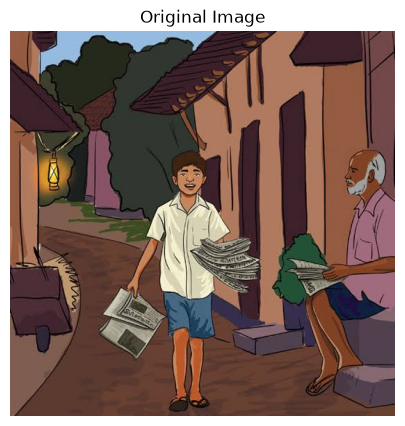

In [19]:
image_path = "images.jpeg"

if not os.path.exists(image_path):
    raise FileNotFoundError("Image file does not exist!")

img_bgr = cv2.imread(image_path)

if img_bgr is None:
    raise ValueError("Image could not be loaded!")

if img_bgr.shape[0] == 0 or img_bgr.shape[1] == 0:
    raise ValueError("Image dimensions are invalid!")

original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

height, width = original.shape[:2]

print("Image Width:", width)
print("Image Height:", height)
print("Image Shape:", original.shape)

plt.figure(figsize=(8, 5))
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()

## 2. Reusable transformation function

The single `transform()` function supports scaling, cropping, flipping, translation, and rotation. All parameters are supplied by the caller. Validation occurs inside the function. Rotation uses the image centre; a positive OpenCV angle is counter-clockwise. Translation keeps the original canvas, so shifted pixels may be clipped and newly exposed areas are black.

In [20]:
MAX_OUTPUT_PIXELS = 40000000

INTERPOLATIONS = {
    "nearest": cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic": cv2.INTER_CUBIC,
    "lanczos": cv2.INTER_LANCZOS4
}


def finite_number(value, name):
    try:
        value = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be numeric.")

    if not math.isfinite(value):
        raise ValueError(f"{name} must be finite.")

    return value


def integer_coordinate(value, name):
    if isinstance(value, bool):
        raise ValueError(f"{name} must be an integer.")

    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be an integer.")

    if not math.isfinite(number) or not number.is_integer():
        raise ValueError(f"{name} must be a finite integer.")

    return int(number)


def check_output_size(w, h):
    if w < 1 or h < 1:
        raise ValueError("Output dimensions must be at least one pixel.")

    if w * h > MAX_OUTPUT_PIXELS:
        raise ValueError("Output image is too large.")


def transform(image, operation, **params):

    if not isinstance(image, np.ndarray) or image.size == 0:
        raise ValueError("Invalid or empty image.")

    if image.ndim not in (2, 3):
        raise ValueError("Invalid image dimensions.")

    h, w = image.shape[:2]

    if h < 1 or w < 1:
        raise ValueError("Image dimensions must be nonzero.")

    if not isinstance(operation, str):
        raise ValueError("Operation must be a string.")

    operation = operation.strip().lower()

    allowed = [
        "scale",
        "crop",
        "flip",
        "translate",
        "rotate",
        "affine"
    ]

    if operation not in allowed:
        raise ValueError("Unknown transformation operation.")

    # SCALING

    if operation == "scale":

        sx = finite_number(params.get("sx"), "sx")
        sy = finite_number(params.get("sy"), "sy")

        if sx <= 0 or sy <= 0:
            raise ValueError("Scale factors must be greater than zero.")

        method = str(params.get("interpolation", "bilinear")).lower()

        if method not in INTERPOLATIONS:
            raise ValueError("Invalid interpolation method.")

        new_w = int(round(w * sx))
        new_h = int(round(h * sy))

        check_output_size(new_w, new_h)

        return cv2.resize(
            image,
            (new_w, new_h),
            interpolation=INTERPOLATIONS[method]
        )

    # CROPPING

    elif operation == "crop":

        left = integer_coordinate(params.get("left"), "left")
        top = integer_coordinate(params.get("top"), "top")
        right = integer_coordinate(params.get("right"), "right")
        bottom = integer_coordinate(params.get("bottom"), "bottom")

        if not (0 <= left < right <= w and
                0 <= top < bottom <= h):

            raise ValueError("Invalid cropping coordinates.")

        return image[top:bottom, left:right].copy()

    # FLIPPING

    elif operation == "flip":

        direction = str(params.get("direction", "")).lower()

        flip_codes = {
            "horizontal": 1,
            "vertical": 0,
            "both": -1
        }

        if direction not in flip_codes:
            raise ValueError("Use horizontal, vertical, or both.")

        return cv2.flip(image, flip_codes[direction])

    # TRANSLATION

    elif operation == "translate":

        tx = finite_number(params.get("tx"), "tx")
        ty = finite_number(params.get("ty"), "ty")

        matrix = np.float32([
            [1, 0, tx],
            [0, 1, ty]
        ])

        return cv2.warpAffine(
            image,
            matrix,
            (w, h),
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

    # ROTATION

    elif operation == "rotate":

        angle = finite_number(params.get("angle"), "angle")
        expand = params.get("expand")

        if not isinstance(expand, (bool, np.bool_)):
            raise ValueError("Expand must be True or False.")

        center = (w / 2, h / 2)

        matrix = cv2.getRotationMatrix2D(
            center,
            angle,
            1.0
        )

        if expand:

            cos_a = abs(matrix[0, 0])
            sin_a = abs(matrix[0, 1])

            new_w = int(math.ceil(
                h * sin_a + w * cos_a
            ))

            new_h = int(math.ceil(
                h * cos_a + w * sin_a
            ))

            check_output_size(new_w, new_h)

            matrix[0, 2] += new_w / 2 - center[0]
            matrix[1, 2] += new_h / 2 - center[1]

        else:
            new_w = w
            new_h = h

        return cv2.warpAffine(
            image,
            matrix,
            (new_w, new_h),
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

    # AFFINE TRANSFORMATION

    elif operation == "affine":

        dx = finite_number(params.get("dx"), "dx")
        dy = finite_number(params.get("dy"), "dy")

        shear_x = finite_number(params.get("shear_x"), "shear_x")
        shear_y = finite_number(params.get("shear_y"), "shear_y")

        matrix = np.float32([
            [1, shear_x, dx],
            [shear_y, 1, dy]
        ])

        check_output_size(w, h)

        return cv2.warpAffine(
            image,
            matrix,
            (w, h),
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

## 3. Display and save transformed results

In [21]:
output_folder = "outputs"

os.makedirs(output_folder, exist_ok=True)


def show_result(result, title, filename=None):

    h, w = result.shape[:2]

    print("Transformation:", title)
    print("Width:", w)
    print("Height:", h)
    print("Shape:", result.shape)

    plt.figure(figsize=(7, 5))

    plt.imshow(
        result,
        cmap="gray" if result.ndim == 2 else None
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

    if filename:

        path = os.path.join(output_folder, filename)

        if result.ndim == 3:
            save_image = cv2.cvtColor(
                result,
                cv2.COLOR_RGB2BGR
            )
        else:
            save_image = result

        cv2.imwrite(path, save_image)

        print("Image saved:", path)

## task 5 scaling


Transformation: Proportional Enlargement
Width: 831
Height: 831
Shape: (831, 831, 3)


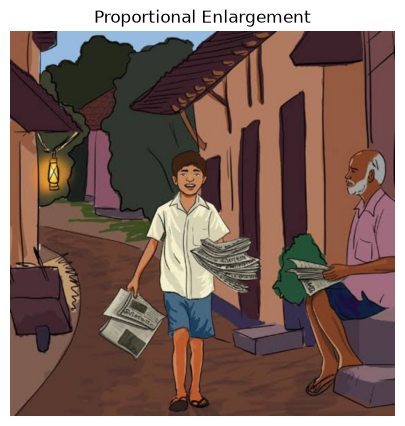

Image saved: outputs\scaled_up.png
Transformation: Proportional Reduction
Width: 277
Height: 277
Shape: (277, 277, 3)


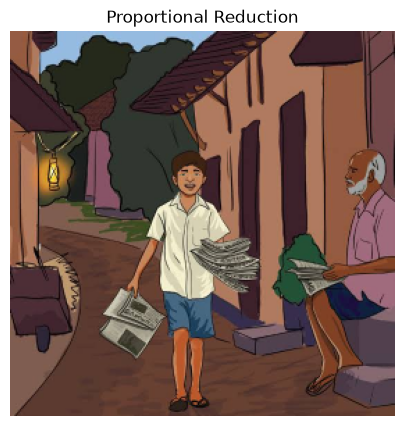

Image saved: outputs\scaled_down.png
Transformation: Non-Proportional Scaling
Width: 831
Height: 388
Shape: (388, 831, 3)


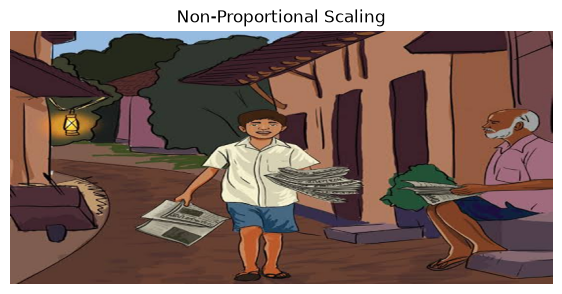

Image saved: outputs\non_proportional.png


In [22]:
# 1. Proportional Enlargement

scaled_up = transform(
    original,
    "scale",
    sx=1.5,
    sy=1.5,
    interpolation="bilinear"
)

show_result(
    scaled_up,
    "Proportional Enlargement",
    "scaled_up.png"
)


# 2. Proportional Reduction

scaled_down = transform(
    original,
    "scale",
    sx=0.5,
    sy=0.5,
    interpolation="bilinear"
)

show_result(
    scaled_down,
    "Proportional Reduction",
    "scaled_down.png"
)


# 3. Non-Proportional Scaling

non_proportional = transform(
    original,
    "scale",
    sx=1.5,
    sy=0.7,
    interpolation="bicubic"
)

show_result(
    non_proportional,
    "Non-Proportional Scaling",
    "non_proportional.png"
)

## 6 croping


Transformation: Cropped Image
Width: 454
Height: 454
Shape: (454, 454, 3)


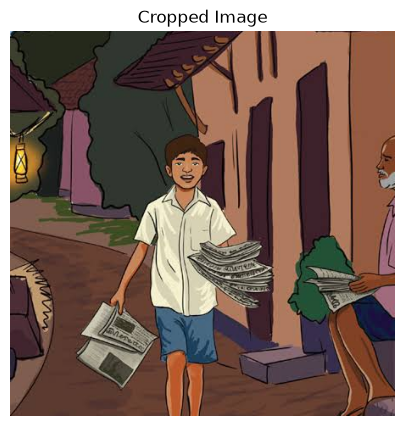

Image saved: outputs\cropped.png


In [23]:
# Cropping an Image

cropped = transform(
    original,
    "crop",
    left=50,
    top=50,
    right=width-50,
    bottom=height-50
)

show_result(
    cropped,
    "Cropped Image",
    "cropped.png"
)

## 7. flipping



Transformation: Horizontal Flip
Width: 554
Height: 554
Shape: (554, 554, 3)


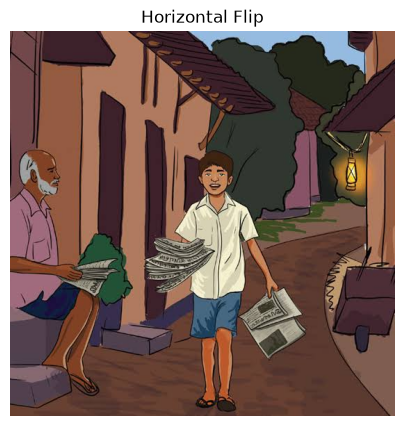

Image saved: outputs\horizontal_flip.png
Transformation: Vertical Flip
Width: 554
Height: 554
Shape: (554, 554, 3)


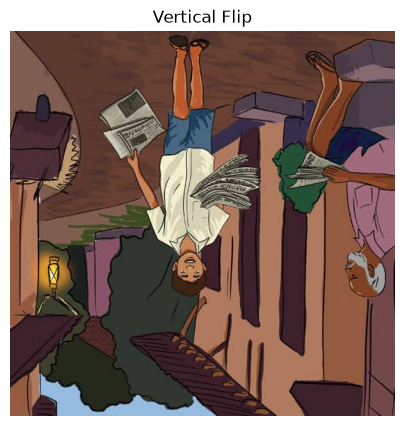

Image saved: outputs\vertical_flip.png
Transformation: Both Horizontal and Vertical Flip
Width: 554
Height: 554
Shape: (554, 554, 3)


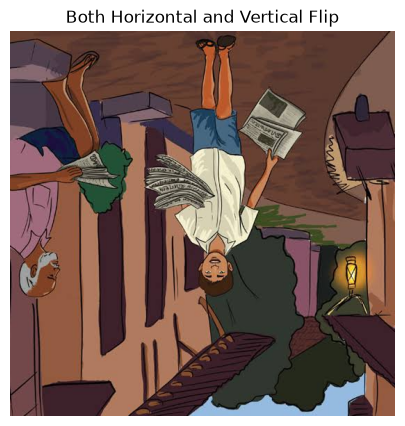

Image saved: outputs\both_flip.png


In [24]:
# 1. Horizontal Flip

horizontal = transform(
    original,
    "flip",
    direction="horizontal"
)

show_result(
    horizontal,
    "Horizontal Flip",
    "horizontal_flip.png"
)


# 2. Vertical Flip

vertical = transform(
    original,
    "flip",
    direction="vertical"
)

show_result(
    vertical,
    "Vertical Flip",
    "vertical_flip.png"
)


# 3. Both Horizontal and Vertical Flip

both = transform(
    original,
    "flip",
    direction="both"
)

show_result(
    both,
    "Both Horizontal and Vertical Flip",
    "both_flip.png"
)

## 8. translation



Transformation: Positive Translation
Width: 554
Height: 554
Shape: (554, 554, 3)


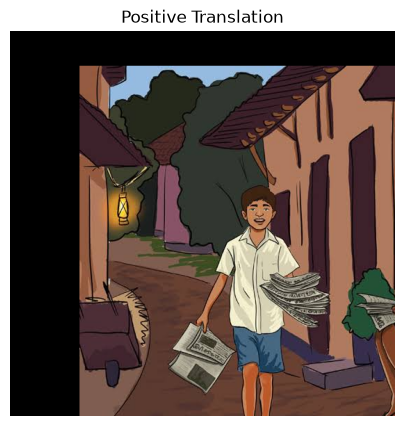

Image saved: outputs\translation_positive.png
Transformation: Negative Translation
Width: 554
Height: 554
Shape: (554, 554, 3)


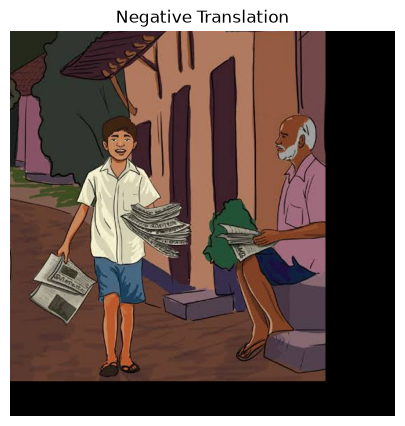

Image saved: outputs\translation_negative.png
Transformation: Zero Translation
Width: 554
Height: 554
Shape: (554, 554, 3)


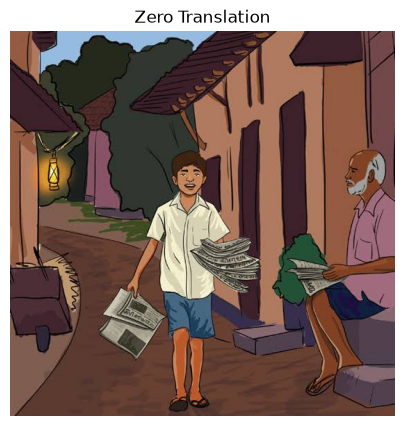

Image saved: outputs\translation_zero.png


In [25]:
# 1. Positive Translation

translated_positive = transform(
    original,
    "translate",
    tx=100,
    ty=50
)

show_result(
    translated_positive,
    "Positive Translation",
    "translation_positive.png"
)


# 2. Negative Translation

translated_negative = transform(
    original,
    "translate",
    tx=-100,
    ty=-50
)

show_result(
    translated_negative,
    "Negative Translation",
    "translation_negative.png"
)


# 3. Zero Translation

translated_zero = transform(
    original,
    "translate",
    tx=0,
    ty=0
)

show_result(
    translated_zero,
    "Zero Translation",
    "translation_zero.png"
)

## 9. rotation


Transformation: Positive Rotation 45 Degrees
Width: 784
Height: 784
Shape: (784, 784, 3)


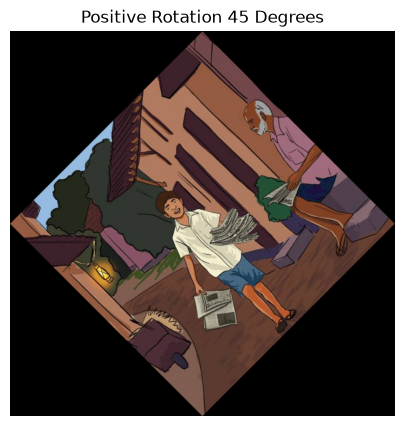

Image saved: outputs\rotation_positive.png
Transformation: Negative Rotation 45 Degrees
Width: 784
Height: 784
Shape: (784, 784, 3)


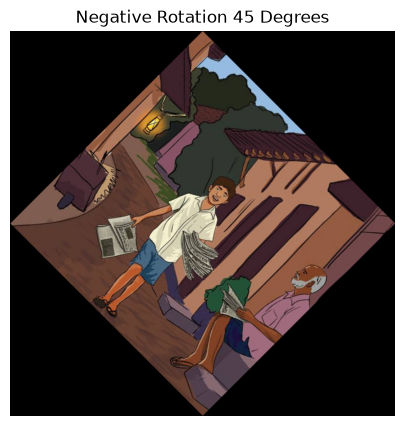

Image saved: outputs\rotation_negative.png
Transformation: Rotation Without Canvas Expansion
Width: 554
Height: 554
Shape: (554, 554, 3)


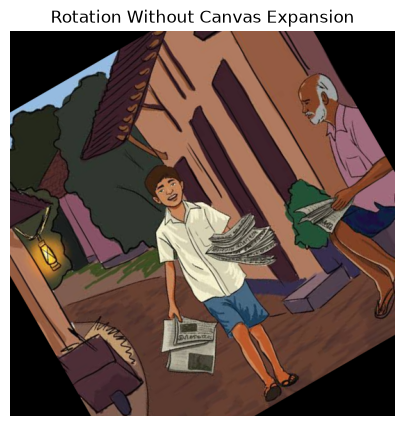

Image saved: outputs\rotation_fixed.png
Transformation: Zero Rotation
Width: 554
Height: 554
Shape: (554, 554, 3)


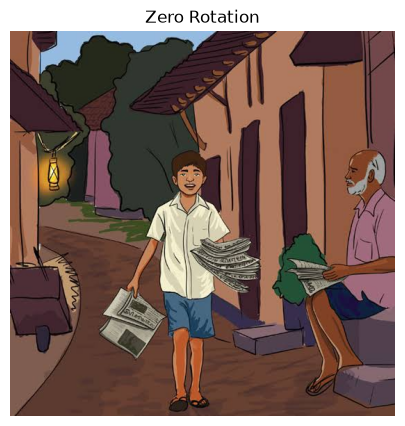

Image saved: outputs\rotation_zero.png


In [26]:
# 1. Positive Rotation

rotated_positive = transform(
    original,
    "rotate",
    angle=45,
    expand=True
)

show_result(
    rotated_positive,
    "Positive Rotation 45 Degrees",
    "rotation_positive.png"
)


# 2. Negative Rotation

rotated_negative = transform(
    original,
    "rotate",
    angle=-45,
    expand=True
)

show_result(
    rotated_negative,
    "Negative Rotation 45 Degrees",
    "rotation_negative.png"
)


# 3. Rotation Without Canvas Expansion

rotated_fixed = transform(
    original,
    "rotate",
    angle=30,
    expand=False
)

show_result(
    rotated_fixed,
    "Rotation Without Canvas Expansion",
    "rotation_fixed.png"
)


# 4. Zero Rotation

rotated_zero = transform(
    original,
    "rotate",
    angle=0,
    expand=False
)

show_result(
    rotated_zero,
    "Zero Rotation",
    "rotation_zero.png"
)

## Affine transformation

Transformation: Affine Transformation
Width: 554
Height: 554
Shape: (554, 554, 3)


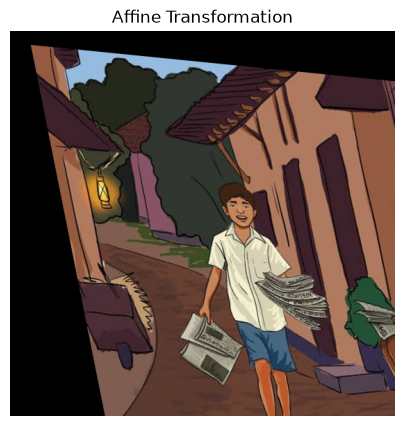

Image saved: outputs\affine.png


In [27]:
# Affine Transformation

affine_result = transform(
    original,
    "affine",
    dx=30,
    dy=20,
    shear_x=0.2,
    shear_y=0.1
)

show_result(
    affine_result,
    "Affine Transformation",
    "affine.png"
)


# interpolation comparison

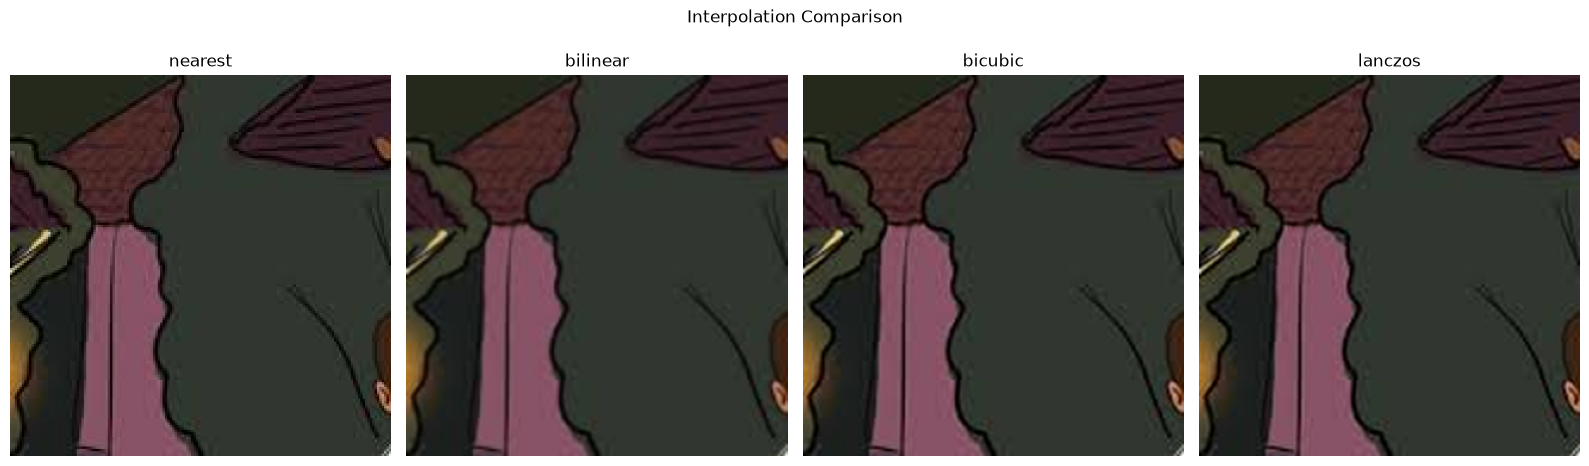

In [28]:
# Interpolation Comparison

patch = original[80:240, 80:240]

interpolation_results = {}

for name, method in INTERPOLATIONS.items():

    result = cv2.resize(
        patch,
        None,
        fx=2,
        fy=2,
        interpolation=method
    )

    interpolation_results[name] = result


fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (name, result) in zip(
    axes,
    interpolation_results.items()
):

    ax.imshow(result)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Interpolation Comparison")
plt.tight_layout()
plt.show()

# input validation

In [29]:
invalid_examples = [

    ("scale", {
        "sx": 0,
        "sy": 1
    }),

    ("crop", {
        "left": 100,
        "top": 100,
        "right": 50,
        "bottom": 200
    }),

    ("flip", {
        "direction": "diagonal"
    }),

    ("translate", {
        "tx": float("nan"),
        "ty": 10
    }),

    ("rotate", {
        "angle": "abc",
        "expand": True
    })
]


for operation, parameters in invalid_examples:

    try:

        transform(
            original,
            operation,
            **parameters
        )

        print("FAIL:", operation)

    except (ValueError, TypeError) as error:

        print("PASS:", operation, "Rejected:", error)

PASS: scale Rejected: Scale factors must be greater than zero.
PASS: crop Rejected: Invalid cropping coordinates.
PASS: flip Rejected: Use horizontal, vertical, or both.
PASS: translate Rejected: tx must be finite.
PASS: rotate Rejected: angle must be numeric.


# identify transformation checks

In [30]:
identity_tests = [

    (
        "Zero Translation",
        transform(
            original,
            "translate",
            tx=0,
            ty=0
        )
    ),

    (
        "Scale Factor One",
        transform(
            original,
            "scale",
            sx=1,
            sy=1,
            interpolation="nearest"
        )
    ),

    (
        "Zero Rotation",
        transform(
            original,
            "rotate",
            angle=0,
            expand=False
        )
    )
]


print("IDENTITY TRANSFORMATION RESULTS")
print("-" * 75)

for name, result in identity_tests:

    passed = (
        result.shape == original.shape
        and np.array_equal(result, original)
    )

    print("Test:", name)
    print("Expected: Original image unchanged")
    print("Actual:", "Unchanged" if passed else "Different")
    print("Result:", "PASS" if passed else "FAIL")
    print("-" * 75)

IDENTITY TRANSFORMATION RESULTS
---------------------------------------------------------------------------
Test: Zero Translation
Expected: Original image unchanged
Actual: Unchanged
Result: PASS
---------------------------------------------------------------------------
Test: Scale Factor One
Expected: Original image unchanged
Actual: Unchanged
Result: PASS
---------------------------------------------------------------------------
Test: Zero Rotation
Expected: Original image unchanged
Actual: Unchanged
Result: PASS
---------------------------------------------------------------------------


# custom user_input


Choose scale, crop, flip, translate, rotate, affine or q to quit:  scale
Enter horizontal scale:  3
Enter vertical scale:  2
Interpolation (nearest/bilinear/bicubic/lanczos):  bilinear


Transformation: User Selected: scale
Width: 1662
Height: 1108
Shape: (1108, 1662, 3)


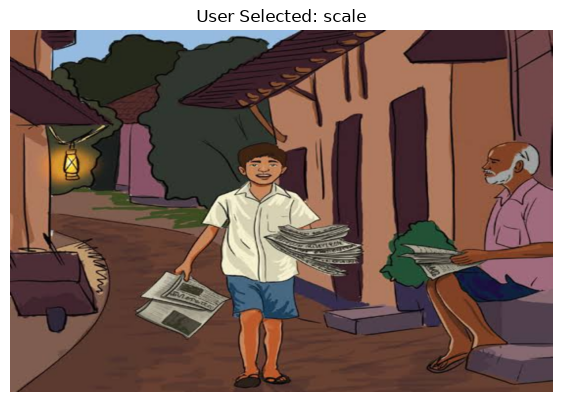

Image saved: outputs\user_result.png



Choose scale, crop, flip, translate, rotate, affine or q to quit:  q


In [31]:
def get_float(message):

    while True:

        try:
            value = float(input(message))

            if not math.isfinite(value):
                raise ValueError("Enter a finite number.")

            return value

        except ValueError as error:
            print("Invalid input:", error)


def get_integer(message):

    while True:

        try:
            return int(input(message))

        except ValueError:
            print("Enter a valid integer.")


def interactive_transform():

    while True:

        operation = input(
            "\nChoose scale, crop, flip, translate, rotate, affine or q to quit: "
        ).lower().strip()

        if operation == "q":
            break

        try:

            if operation == "scale":

                sx = get_float("Enter horizontal scale: ")
                sy = get_float("Enter vertical scale: ")

                method = input(
                    "Interpolation (nearest/bilinear/bicubic/lanczos): "
                ).lower()

                result = transform(
                    original, operation,
                    sx=sx, sy=sy,
                    interpolation=method
                )

            elif operation == "crop":

                left = get_integer("Enter left: ")
                top = get_integer("Enter top: ")
                right = get_integer("Enter right: ")
                bottom = get_integer("Enter bottom: ")

                result = transform(
                    original, operation,
                    left=left, top=top,
                    right=right, bottom=bottom
                )

            elif operation == "flip":

                direction = input(
                    "Enter horizontal, vertical, or both: "
                )

                result = transform(
                    original, operation,
                    direction=direction
                )

            elif operation == "translate":

                tx = get_float("Enter horizontal offset: ")
                ty = get_float("Enter vertical offset: ")

                result = transform(
                    original, operation,
                    tx=tx, ty=ty
                )

            elif operation == "rotate":

                angle = get_float("Enter rotation angle: ")

                choice = input(
                    "Expand canvas? (yes/no): "
                ).lower()

                if choice not in ("yes", "no"):
                    raise ValueError("Enter yes or no.")

                result = transform(
                    original, operation,
                    angle=angle,
                    expand=(choice == "yes")
                )

            elif operation == "affine":

                dx = get_float("Enter dx: ")
                dy = get_float("Enter dy: ")
                shx = get_float("Enter shear x: ")
                shy = get_float("Enter shear y: ")

                result = transform(
                    original, operation,
                    dx=dx, dy=dy,
                    shear_x=shx,
                    shear_y=shy
                )

            else:

                raise ValueError("Unknown operation.")

            show_result(
                result,
                "User Selected: " + operation,
                "user_result.png"
            )

        except (ValueError, TypeError) as error:

            print("Error:", error)
            print("Please enter the values again.")


interactive_transform()